In [1]:

# ==========================================
# TERRASPECTRA CNN V4
# STEP 17: MOBILE NET V2 SETUP
# ==========================================

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow:", tf.__version__)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS_HEAD = 15
EPOCHS_FINE = 15

NUM_CLASSES = 4

CLASS_NAMES = [
    "Black rot",
    "Esca",
    "Healthy",
    "Leaf blight"
]

SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("\nMobileNetV2 setup completed!")


TensorFlow: 2.21.0

MobileNetV2 setup completed!


In [3]:

# ==========================================
# STEP 17.1: LOAD FINAL DATASETS
# ==========================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits_final"

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

# Class mapping
class_to_index = {
    "black rot": 0,
    "esca": 1,
    "healthy": 2,
    "leaf blight": 3
}

def encode_labels(df):
    labels = (
        df["label"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(class_to_index)
    )

    if labels.isna().any():
        raise ValueError(
            f"Unknown labels: {df.loc[labels.isna(), 'label'].unique()}"
        )

    return labels.to_numpy(dtype=np.int32)


train_labels = encode_labels(train_df)
val_labels = encode_labels(val_df)
test_labels = encode_labels(test_df)


# Resolve image paths
def resolve_image_path(value):
    path = Path(str(value).replace("\\", "/"))

    if path.is_absolute():
        return str(path)

    parts = list(path.parts)

    if parts and parts[0] == "..":
        parts = parts[1:]

    return str(PROJECT_ROOT.joinpath(*parts))


train_paths = train_df["image_path"].apply(
    resolve_image_path
).values

val_paths = val_df["image_path"].apply(
    resolve_image_path
).values

test_paths = test_df["image_path"].apply(
    resolve_image_path
).values


# Verify paths
for name, paths in [
    ("Train", train_paths),
    ("Validation", val_paths),
    ("Test", test_paths)
]:
    missing = [p for p in paths if not Path(p).exists()]
    print(f"{name}: {len(paths)} images | Missing: {len(missing)}")

    if missing:
        raise FileNotFoundError(missing[:5])

print("\nDataset loading completed!")
print("Train:", len(train_labels))
print("Validation:", len(val_labels))
print("Test:", len(test_labels))


Train: 1730 images | Missing: 0
Validation: 341 images | Missing: 0
Test: 336 images | Missing: 0

Dataset loading completed!
Train: 1730
Validation: 341
Test: 336


In [4]:

# ==========================================
# STEP 18: MOBILENETV2 DATA PIPELINE
# ==========================================

AUTOTUNE = tf.data.AUTOTUNE

def load_mobilenet_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    image = preprocess_input(image)

    return image, label


def create_mobilenet_dataset(paths, labels, training=False):

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_mobilenet_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds_v4 = create_mobilenet_dataset(
    train_paths,
    train_labels,
    training=True
)

val_ds_v4 = create_mobilenet_dataset(
    val_paths,
    val_labels
)

test_ds_v4 = create_mobilenet_dataset(
    test_paths,
    test_labels
)

print("MobileNetV2 datasets created!")

images, labels = next(iter(train_ds_v4))

print("Image shape:", images.shape)
print("Minimum pixel:", tf.reduce_min(images).numpy())
print("Maximum pixel:", tf.reduce_max(images).numpy())


MobileNetV2 datasets created!
Image shape: (16, 224, 224, 3)
Minimum pixel: -1.0
Maximum pixel: 1.0


In [5]:

# ==========================================
# STEP 19: MODERATED CLASS WEIGHTS
# ==========================================

class_counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES
)

# Inverse-frequency weights with square-root moderation
raw_weights = (
    len(train_labels) /
    (NUM_CLASSES * class_counts)
)

moderated_weights = np.sqrt(raw_weights)

# Normalize weights to have mean 1
moderated_weights = (
    moderated_weights /
    moderated_weights.mean()
)

class_weights_v4 = {
    int(i): float(weight)
    for i, weight in enumerate(moderated_weights)
}

print("CLASS DISTRIBUTION AND WEIGHTS\n")

for i, name in enumerate(CLASS_NAMES):
    print(
        f"{name}: "
        f"Images={class_counts[i]}, "
        f"Weight={class_weights_v4[i]:.4f}"
    )


CLASS DISTRIBUTION AND WEIGHTS

Black rot: Images=72, Weight=1.8244
Esca: Images=635, Weight=0.6143
Healthy: Images=788, Weight=0.5515
Leaf blight: Images=235, Weight=1.0098


In [6]:

# ==========================================
# STEP 20: BUILD MOBILENETV2 MODEL
# ==========================================

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained backbone
base_model.trainable = False

inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

# Training=False keeps Batch Normalization stable
x = base_model(
    inputs,
    training=False
)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.3)(x)

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model_v4 = tf.keras.Model(
    inputs,
    outputs,
    name="TerraSpectra_MobileNetV2_v4"
)

model_v4.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v4.summary()


Model: "TerraSpectra_MobileNetV2_v4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:

# ==========================================
# STEP 21: CONFIGURE CALLBACKS
# ==========================================

MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

MODEL_DIR.mkdir(exist_ok=True, parents=True)
REPORT_DIR.mkdir(exist_ok=True, parents=True)

checkpoint_v4 = (
    MODEL_DIR / "mobilenetv2_v4_best.keras"
)

callbacks_v4 = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_v4),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configured.")
print("Checkpoint:", checkpoint_v4)


Callbacks configured.
Checkpoint: c:\intern project 2\TerraSpectra-\models\mobilenetv2_v4_best.keras


In [8]:

# ==========================================
# STEP 22: MOBILENETV2 PHASE 1 TRAINING
# ==========================================

history_v4_phase1 = model_v4.fit(
    train_ds_v4,
    validation_data=val_ds_v4,
    epochs=15,
    class_weight=class_weights_v4,
    callbacks=callbacks_v4,
    verbose=1
)

print("\nPHASE 1 TRAINING COMPLETED!")

print("Best checkpoint:", checkpoint_v4)


Epoch 1/15


c:\Users\shewa\anaconda3\envs\terraspectra\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.5723 - loss: 0.8744
Epoch 1: val_loss improved from None to 0.62697, saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_v4_best.keras

Epoch 1: finished saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_v4_best.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 32s 240ms/step - accuracy: 0.5723 - loss: 0.8744 - val_accuracy: 0.7947 - val_loss: 0.6270 - learning_rate: 1.0000e-04
Epoch 2/15
108/109 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.7124 - loss: 0.5939
Epoch 2: val_loss improved from 0.62697 to 0.50909, saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_v4_best.keras

Epoch 2: finished saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_v4_best.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 24s 218ms/step - accuracy: 0.7121 - loss: 0.5960 - val_accuracy: 0.8211 - val_loss: 0.5091 - learning_rate: 1.0000e-04
Epoch 3/15
108/109 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.

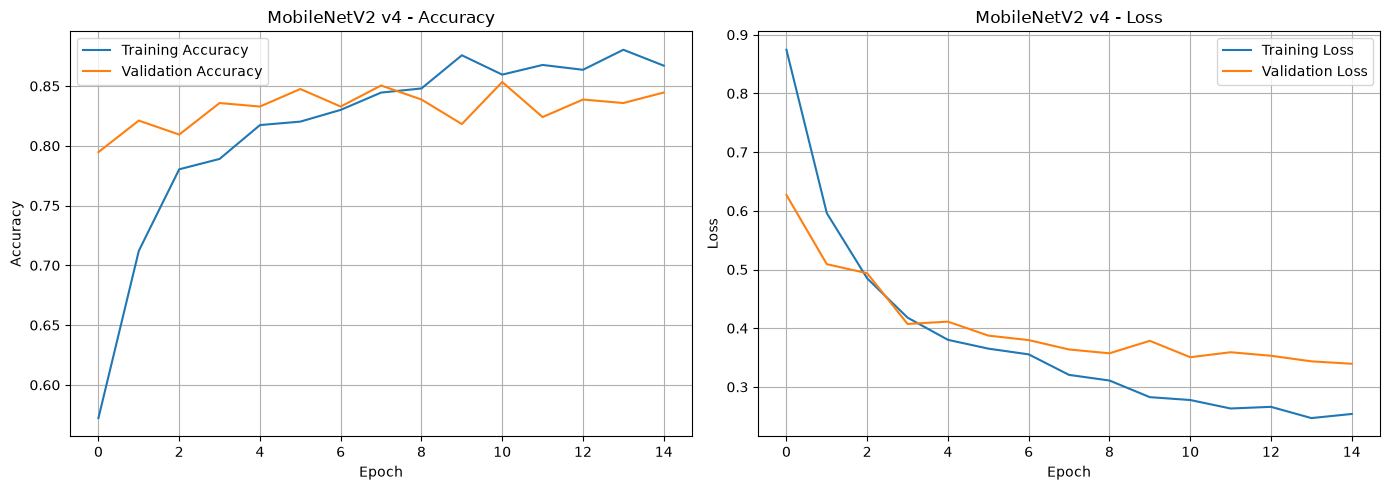

Best validation accuracy: 0.8533724546432495
Best validation loss: 0.33941179513931274
Best accuracy epoch: 11


In [9]:

# ==========================================
# STEP 23: PHASE 1 TRAINING CURVES
# ==========================================

history_v4_df = pd.DataFrame(
    history_v4_phase1.history
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    history_v4_df["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history_v4_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("MobileNetV2 v4 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    history_v4_df["loss"],
    label="Training Loss"
)

axes[1].plot(
    history_v4_df["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("MobileNetV2 v4 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best validation accuracy:",
      history_v4_df["val_accuracy"].max())

print("Best validation loss:",
      history_v4_df["val_loss"].min())

print("Best accuracy epoch:",
      history_v4_df["val_accuracy"].idxmax() + 1)


In [10]:

# ==========================================
# STEP 24: PHASE 1 VALIDATION REPORT
# ==========================================

# Use the best checkpoint saved during Phase 1
model_v4 = tf.keras.models.load_model(
    checkpoint_v4
)

val_prob_v4 = model_v4.predict(
    val_ds_v4,
    verbose=1
)

val_pred_v4 = np.argmax(
    val_prob_v4,
    axis=1
)

print("\nVALIDATION CLASSIFICATION REPORT")

print(classification_report(
    val_labels,
    val_pred_v4,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nPREDICTED CLASS DISTRIBUTION")

print(pd.Series(val_pred_v4).map(
    {i: name for i, name in enumerate(CLASS_NAMES)}
).value_counts())


22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 238ms/step

VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Black rot       0.68      0.93      0.79        14
        Esca       0.80      0.82      0.81       125
     Healthy       0.98      0.99      0.98       155
 Leaf blight       0.51      0.40      0.45        47

    accuracy                           0.84       341
   macro avg       0.74      0.79      0.76       341
weighted avg       0.84      0.84      0.84       341


PREDICTED CLASS DISTRIBUTION
Healthy        156
Esca           129
Leaf blight     37
Black rot       19
Name: count, dtype: int64


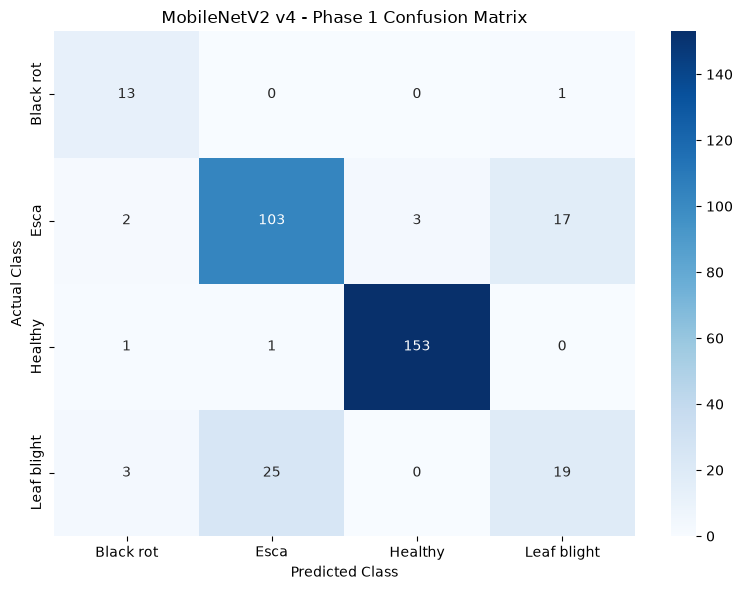

In [11]:

cm_v4 = confusion_matrix(
    val_labels,
    val_pred_v4,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_v4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("MobileNetV2 v4 - Phase 1 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [12]:

# ==========================================
# STEP 26: FINE-TUNING CONFIGURATION
# ==========================================

# Get pretrained MobileNetV2 backbone
base_model_v4 = model_v4.get_layer(
    "mobilenetv2_1.00_224"
)

# Enable fine-tuning
base_model_v4.trainable = True

# Freeze earlier layers
for layer in base_model_v4.layers[:-30]:
    layer.trainable = False

# Always keep Batch Normalization frozen
for layer in base_model_v4.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total backbone layers:", len(base_model_v4.layers))

print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model_v4.layers)
)

print("Batch Normalization layers remain frozen.")


Total backbone layers: 154
Trainable backbone layers: 19
Batch Normalization layers remain frozen.


In [13]:

# ==========================================
# STEP 27: RECOMPILE FOR FINE-TUNING
# ==========================================

model_v4.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning compilation completed.")
print("Learning rate: 0.00001")


Fine-tuning compilation completed.
Learning rate: 0.00001


In [14]:

# ==========================================
# STEP 28: MACRO F1 CHECKPOINT CALLBACK
# ==========================================

class MacroF1Checkpoint(tf.keras.callbacks.Callback):

    def __init__(self, validation_data, save_path, patience=4):
        super().__init__()

        self.validation_data = validation_data
        self.save_path = str(save_path)
        self.patience = patience
        self.best_f1 = -1
        self.wait = 0

    def on_epoch_end(self, epoch, logs=None):

        probabilities = self.model.predict(
            self.validation_data,
            verbose=0
        )

        predictions = np.argmax(probabilities, axis=1)

        actual = self.validation_data.y.numpy() if hasattr(
            self.validation_data, "y"
        ) else None

        if actual is None:
            actual = val_labels

        score = f1_score(
            actual,
            predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )

        print(f"\nValidation Macro F1: {score:.4f}")

        if score > self.best_f1:

            self.best_f1 = score
            self.wait = 0

            self.model.save(self.save_path)

            print("New best macro F1 model saved.")

        else:

            self.wait += 1

            if self.wait >= self.patience:
                print("Early stopping: macro F1 did not improve.")
                self.model.stop_training = True


checkpoint_v4_finetuned = (
    MODEL_DIR / "mobilenetv2_v4_finetuned_best.keras"
)

macro_f1_callback = MacroF1Checkpoint(
    validation_data=val_ds_v4,
    save_path=checkpoint_v4_finetuned,
    patience=4
)

reduce_lr_v4 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

print("Macro F1 checkpoint configured.")


Macro F1 checkpoint configured.


In [15]:

# ==========================================
# STEP 29: MOBILENETV2 FINE-TUNING
# ==========================================

history_v4_phase2 = model_v4.fit(
    train_ds_v4,
    validation_data=val_ds_v4,
    epochs=12,
    class_weight=class_weights_v4,
    callbacks=[
        macro_f1_callback,
        reduce_lr_v4
    ],
    verbose=1
)

print("\nPHASE 2 FINE-TUNING COMPLETED!")

print("Best macro F1:", macro_f1_callback.best_f1)
print("Checkpoint:", checkpoint_v4_finetuned)


Epoch 1/12


c:\Users\shewa\anaconda3\envs\terraspectra\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.8757 - loss: 0.2489
Validation Macro F1: 0.7672
New best macro F1 model saved.
109/109 ━━━━━━━━━━━━━━━━━━━━ 41s 324ms/step - accuracy: 0.8757 - loss: 0.2489 - val_accuracy: 0.8299 - val_loss: 0.3441 - learning_rate: 1.0000e-05
Epoch 2/12
108/109 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.8976 - loss: 0.2128
Validation Macro F1: 0.7816
New best macro F1 model saved.
109/109 ━━━━━━━━━━━━━━━━━━━━ 32s 294ms/step - accuracy: 0.8977 - loss: 0.2126 - val_accuracy: 0.8416 - val_loss: 0.3296 - learning_rate: 1.0000e-05
Epoch 3/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.8931 - loss: 0.2068
Validation Macro F1: 0.7758
109/109 ━━━━━━━━━━━━━━━━━━━━ 33s 300ms/step - accuracy: 0.8931 - loss: 0.2068 - val_accuracy: 0.8534 - val_loss: 0.3054 - learning_rate: 1.0000e-05
Epoch 4/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.9081 - loss: 0.1964
Validation Macro F1: 0.7528
109/109 ━━━━━━━━━━━━━━━━━━━━ 33s 297ms/st

In [16]:

# ==========================================
# STEP 30: COMPARE PHASE 1 AND PHASE 2
# ==========================================

phase1_model = tf.keras.models.load_model(
    checkpoint_v4
)

phase2_model = tf.keras.models.load_model(
    checkpoint_v4_finetuned
)

def evaluate_validation(model, model_name):

    probabilities = model.predict(
        val_ds_v4,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    accuracy = accuracy_score(
        val_labels,
        predictions
    )

    macro_f1 = f1_score(
        val_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    print(f"\n{model_name}")
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    print("\nClassification Report:")

    print(classification_report(
        val_labels,
        predictions,
        labels=[0, 1, 2, 3],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    return {
        "model": model_name,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }


phase1_result = evaluate_validation(
    phase1_model,
    "MobileNetV2 Phase 1"
)

phase2_result = evaluate_validation(
    phase2_model,
    "MobileNetV2 Phase 2"
)

comparison_df = pd.DataFrame([
    phase1_result,
    phase2_result
])

print("\nMODEL COMPARISON")
display(comparison_df)



MobileNetV2 Phase 1
Accuracy: 0.8446
Macro F1: 0.7588

Classification Report:
              precision    recall  f1-score   support

   Black rot       0.68      0.93      0.79        14
        Esca       0.80      0.82      0.81       125
     Healthy       0.98      0.99      0.98       155
 Leaf blight       0.51      0.40      0.45        47

    accuracy                           0.84       341
   macro avg       0.74      0.79      0.76       341
weighted avg       0.84      0.84      0.84       341


MobileNetV2 Phase 2
Accuracy: 0.8416
Macro F1: 0.7816

Classification Report:
              precision    recall  f1-score   support

   Black rot       0.81      0.93      0.87        14
        Esca       0.81      0.78      0.79       125
     Healthy       0.99      0.99      0.99       155
 Leaf blight       0.46      0.49      0.47        47

    accuracy                           0.84       341
   macro avg       0.77      0.80      0.78       341
weighted avg       0.84    

,model,accuracy,macro_f1
0,MobileNetV2 Phase 1,0.844575,0.758802
1,MobileNetV2 Phase 2,0.841642,0.781570


In [17]:

# ==========================================
# STEP 31: SAVE SELECTED MODEL
# ==========================================

selected_model = tf.keras.models.load_model(
    checkpoint_v4_finetuned
)

selected_model_path = (
    MODEL_DIR / "terraspectra_mobilenetv2_final.keras"
)

selected_model.save(selected_model_path)

print("Selected model saved successfully!")
print("Model:", selected_model_path)
print("Selected version: MobileNetV2 Phase 2")
print("Validation Macro F1: 0.7816")


Selected model saved successfully!
Model: c:\intern project 2\TerraSpectra-\models\terraspectra_mobilenetv2_final.keras
Selected version: MobileNetV2 Phase 2
Validation Macro F1: 0.7816


In [18]:

# ==========================================
# STEP 32: FINAL TEST EVALUATION
# ==========================================

test_probabilities = selected_model.predict(
    test_ds_v4,
    verbose=1
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

print("\n========== TERRASPECTRA FINAL TEST RESULTS ==========")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print(f"Test Weighted F1: {test_weighted_f1:.4f}")

print("\nFINAL CLASSIFICATION REPORT")

print(classification_report(
    test_labels,
    test_predictions,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    zero_division=0
))


21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 214ms/step

========== TERRASPECTRA FINAL TEST RESULTS ==========
Test Accuracy: 0.8393
Test Macro F1: 0.7610
Test Weighted F1: 0.8433

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Black rot       0.73      0.73      0.73        11
        Esca       0.83      0.78      0.80       126
     Healthy       0.99      0.99      0.99       150
 Leaf blight       0.48      0.57      0.52        49

    accuracy                           0.84       336
   macro avg       0.76      0.77      0.76       336
weighted avg       0.85      0.84      0.84       336



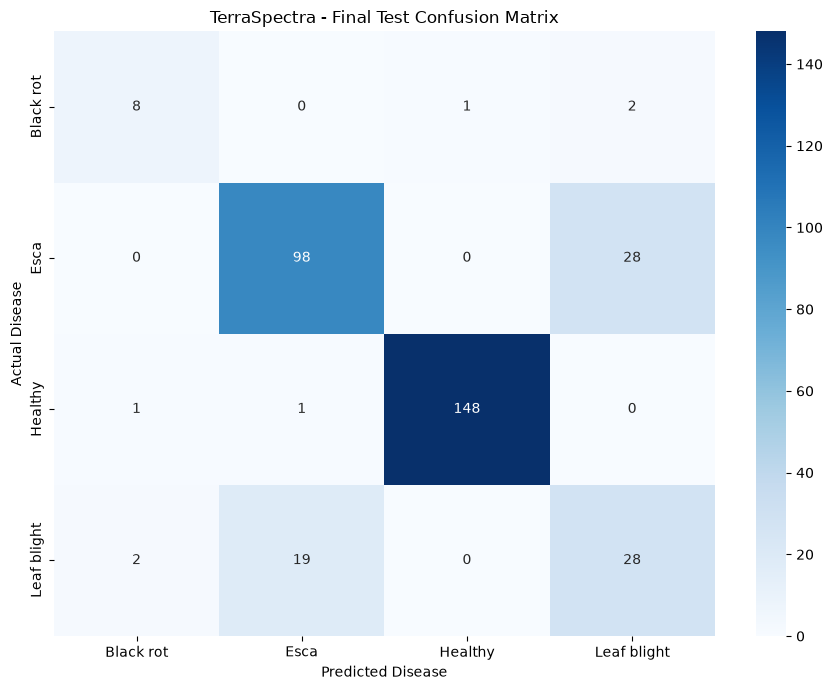

In [19]:

# ==========================================
# STEP 33: FINAL TEST CONFUSION MATRIX
# ==========================================

cm_final = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("TerraSpectra - Final Test Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "terraspectra_final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

# ==========================================
# STEP 34: SAVE FINAL MODEL METADATA
# ==========================================

import json
from sklearn.metrics import classification_report

# Classification report
report = classification_report(
    test_labels,
    test_predictions,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    REPORT_DIR / "final_classification_report.csv"
)

# Final metrics
metrics = {
    "model_name": "TerraSpectra MobileNetV2 v4",
    "architecture": "MobileNetV2 Transfer Learning",
    "input_size": [224, 224, 3],
    "class_names": CLASS_NAMES,
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "validation_macro_f1": 0.7815696481,
    "test_images": int(len(test_labels)),
    "training_images": 1730,
    "validation_images": 341,
    "preprocessing": "MobileNetV2 preprocess_input",
    "model_file": "terraspectra_mobilenetv2_final.keras",
    "known_limitation": (
        "Leaf blight and Esca confusion; "
        "limited Black rot test support; "
        "representative-vineyard split limitation."
    )
}

with open(
    REPORT_DIR / "model_metrics.json",
    "w"
) as file:
    json.dump(metrics, file, indent=4)

print("Final reports saved successfully!")

print("Classification report:",
      REPORT_DIR / "final_classification_report.csv")

print("Model metadata:",
      REPORT_DIR / "model_metrics.json")


Final reports saved successfully!
Classification report: c:\intern project 2\TerraSpectra-\reports\final_classification_report.csv
Model metadata: c:\intern project 2\TerraSpectra-\reports\model_metrics.json


In [22]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

CLASS_NAMES = [
    "Black rot",
    "Esca",
    "Healthy",
    "Leaf blight"
]

reference_df = test_df.copy()

reference_df["notebook_predicted_index"] = test_predictions

reference_df["notebook_predicted_disease"] = [
    CLASS_NAMES[int(i)] for i in test_predictions
]

output_path = (
    PROJECT_ROOT
    / "reports"
    / "notebook_test_predictions.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

reference_df.to_csv(output_path, index=False)

print("Notebook reference predictions saved successfully!")
print("Total predictions:", len(reference_df))
print("Saved to:", output_path)


Notebook reference predictions saved successfully!
Total predictions: 336
Saved to: c:\intern project 2\TerraSpectra-\reports\notebook_test_predictions.csv


In [23]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
REPORT_DIR = PROJECT_ROOT / "reports"

# Load both prediction files
notebook_df = pd.read_csv(
    REPORT_DIR / "notebook_test_predictions.csv"
)

standalone_df = pd.read_csv(
    REPORT_DIR / "standalone_test_predictions.csv"
)

# Compare predictions using image paths
comparison_df = notebook_df[
    ["image_path", "label", "notebook_predicted_index"]
].merge(
    standalone_df[
        ["image_path", "label", "predicted_index"]
    ],
    on="image_path",
    how="inner",
    suffixes=("_notebook", "_standalone"),
    validate="one_to_one"
)

# Verify actual labels also match
labels_match = (
    comparison_df["label_notebook"].str.strip().str.lower()
    == comparison_df["label_standalone"].str.strip().str.lower()
).all()

# Compare predicted classes
comparison_df["prediction_match"] = (
    comparison_df["notebook_predicted_index"]
    == comparison_df["predicted_index"]
)

matches = int(comparison_df["prediction_match"].sum())
total = len(comparison_df)

print("=" * 50)
print("NOTEBOOK VS STANDALONE INFERENCE")
print("=" * 50)

print("Notebook predictions:", len(notebook_df))
print("Standalone predictions:", len(standalone_df))
print("Matched image paths:", total)
print("Actual labels match:", labels_match)
print("Identical predictions:", matches, "/", total)

if total > 0:
    print(
        "Prediction parity:",
        round((matches / total) * 100, 2),
        "%"
    )

print("\nVerification status:")

if total == 336 and labels_match and matches == 336:
    print("SUCCESS: All 336 predictions match!")
else:
    print("MISMATCH: Investigate the differences.")

# Save comparison report
comparison_df.to_csv(
    REPORT_DIR / "inference_parity_comparison.csv",
    index=False
)

print("\nComparison report saved successfully!")


NOTEBOOK VS STANDALONE INFERENCE
Notebook predictions: 336
Standalone predictions: 336
Matched image paths: 336
Actual labels match: True
Identical predictions: 336 / 336
Prediction parity: 100.0 %

Verification status:
SUCCESS: All 336 predictions match!

Comparison report saved successfully!
